# 08_advanced_training
실제 학습/평가 결과를 읽는 실행 가능한 분석 노트북. 원자료 학습 재실행은 run_phase2.ps1 참조.


In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path.cwd()
if not (ROOT/'reports').exists(): ROOT=ROOT.parent
display(Markdown((ROOT/'reports/markdown/08_model_performance.md').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT/'reports/tables/phase2/validation_temporal.csv').head(70))


# 모델 성능 비교

## 공통 Test 시점, 3개 seed 평균

| model | features | detection_f1_mean | detection_f1_sd | diagnosis_macro_f1_mean | diagnosis_macro_f1_sd | sample_FAR_mean | end_to_end_macro_f1_mean |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CNN1D | Temporal | 0.9333 | 0.0027 | 0.9180 | 0.0024 | 0.0110 | 0.8632 |
| LSTM | Temporal | 0.9315 | 0.0050 | 0.9159 | 0.0046 | 0.0110 | 0.8602 |
| GRU | Temporal | 0.9310 | 0.0032 | 0.9121 | 0.0031 | 0.0096 | 0.8577 |
| XGBoost | Statistical | 0.9052 | 0.0004 | 0.8940 | 0.0004 | 0.0072 | 0.8159 |
| LogisticRegression | Statistical | 0.8919 | 0.0000 | 0.8560 | 0.0000 | 0.0085 | 0.7871 |
| RandomForest | Statistical | 0.8910 | 0.0009 | 0.8608 | 0.0010 | 0.0077 | 0.7932 |
| XGBoost | Current | 0.8529 | 0.0017 | 0.8035 | 0.0010 | 0.0110 | 0.7378 |
| RandomForest | Current | 0.8009 | 0.0031 | 0.7378 | 0.0027 | 0.0103 | 0.6634 |
| LogisticRegression | Current | 0.7183 | 0.0000 | 0.5161 | 0.0000 | 0.0105 | 0.4709 |

![모델 비교](../figures/phase2/model_comparison.png)

모델 선정은 Validation 점수로 수행했다. Test 순위가 다르더라도 주 모델을 바꾸지 않았다. conditional diagnosis는 실제 고장 구간을 알고 있다고 가정한20종 분류이며, gated end-to-end는 탐지 실패까지 반영한21상태 지표다.

## 선택 주 모델의 모든 유효 Test 시점

| detection_precision | detection_recall | detection_f1 | detection_macro_f1 | detection_balanced_accuracy | detection_roc_auc | detection_pr_auc | sample_false_alarm_rate | threshold | samples | diagnosis_macro_precision | diagnosis_macro_recall | diagnosis_macro_f1 | diagnosis_balanced_accuracy | end_to_end_macro_f1 | diagnosis_roc_auc_macro_ovr | diagnosis_pr_auc_macro | normal_faultfree_FAR | pre_injection_FAR |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.9970 | 0.8674 | 0.9277 | 0.8512 | 0.9282 | 0.9539 | 0.9901 | 0.0111 | 0.9672 | 9880500 | 0.9236 | 0.9136 | 0.9115 | 0.9136 | 0.8558 | 0.9937 | 0.9268 | 0.0124 | 0.0107 |

| metric | lower_95 | upper_95 |
| --- | --- | --- |
| detection_f1 | 0.9273 | 0.9280 |
| sample_false_alarm_rate | 0.0094 | 0.0129 |
| diagnosis_macro_f1 | 0.9107 | 0.9124 |
| end_to_end_macro_f1 | 0.8551 | 0.8565 |

정상 전용 실행 FAR: 1.24%. 고장 실행의 주입 전 FAR: 1.07%. 위 수치는 단일 샘플 임계값 초과율이다. 정상 전용 경보 episode는 시간당 0.02997개다. 연속3개 규칙을 적용한 실행 검출률과는 다르다.

![Confusion matrix](../figures/phase2/primary_confusion.png)

정밀도/재현율/F1/support 전체는 primary_dense_classification_report.csv, 조건부 고장 Confusion Matrix는 primary_conditional_diagnosis_confusion.npy, 경보 적용21상태 matrix는 primary_dense_confusion.npy다. PR-AUC는 average precision 정의를 사용하며 사다리꼴 적분값과 구분한다. Macro ROC-AUC는 OVR 평균이다.

## 별도 이진 탐지기와 불균형 처리

| detection_precision | detection_recall | detection_f1 | detection_macro_f1 | detection_balanced_accuracy | detection_roc_auc | detection_pr_auc | sample_false_alarm_rate | threshold | samples |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.9970 | 0.8098 | 0.8937 | 0.8004 | 0.8997 | 0.9394 | 0.9866 | 0.0105 | 0.5490 | 9880500 |

| model_id | weight | seed | train_rows | detection_f1_validation | detection_f1_test | sample_false_alarm_rate |
| --- | --- | --- | --- | --- | --- | --- |
| BinaryXGBoost_Statistical_natural_s42 | natural | 42 | 101200 | 0.8811 | 0.8905 | 0.0085 |
| BinaryXGBoost_Statistical_natural_s7 | natural | 7 | 101200 | 0.8833 | 0.8922 | 0.0095 |
| BinaryXGBoost_Statistical_natural_s2026 | natural | 2026 | 101200 | 0.8807 | 0.8900 | 0.0084 |
| BinaryXGBoost_Statistical_balanced_s42 | balanced | 42 | 101200 | 0.8880 | 0.8960 | 0.0101 |
| BinaryXGBoost_Statistical_balanced_s7 | balanced | 7 | 101200 | 0.8891 | 0.8967 | 0.0109 |
| BinaryXGBoost_Statistical_balanced_s2026 | balanced | 2026 | 101200 | 0.8884 | 0.8963 | 0.0106 |
| BinaryXGBoost_Statistical_undersample_s42 | undersample | 42 | 10400 | 0.8818 | 0.8909 | 0.0082 |
| BinaryXGBoost_Statistical_oversample_s42 | oversample | 42 | 192000 | 0.8883 | 0.8962 | 0.0102 |

이진 탐지기는 정상/고장만 예측하며 고장 ID를 주 모델 대신 결정하지 않는다. 두 모델을 결합한 새로운 cascade의 성능을 이 보고서에서 주장하지 않았다. oversampling/undersampling 비교는 seed42 탐색이며 natural/balanced는3개 seed로 확인했다. Joint21클래스는 정상과 개별 고장이 비슷한 크기라 balanced 효과가 작을 수 있지만, 이진 문제에서는 고장 총수가 훨씬 크다.


## 출처 및 재현

- 데이터: Harvard Dataverse V1.0, https://doi.org/10.7910/DVN/6C3JR1 . RData 4개의 공식 MD5 일치를 Phase 1에서 확인했다.
- 공정·공개 고장 참조: https://github.com/Blound04/tennessee-eastman-dataset . Dataset A는 학습에 사용하지 않았다. A의 물리 정의를 B 구현과 완전히 동일하다고 가정하지 않았다.
- API: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [XGBoost](https://xgboost.readthedocs.io/en/stable/gpu/index.html), [PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.rnn.LSTM.html).
- 실제 설정: configs/phase2.json, 모델 선택 기록: models/phase2/selection_lock.json. 표·그림은 reports/tables/phase2, reports/figures/phase2에 있다.


,model_id,family,feature,seed,weight,epoch,selection_score,device,train_rows,validation_rows,...,sample_false_alarm_rate,threshold,samples,diagnosis_macro_precision,diagnosis_macro_recall,diagnosis_macro_f1,diagnosis_balanced_accuracy,end_to_end_macro_f1,training_seconds,model_bytes
0,LSTM_Temporal_balanced_s42,LSTM,Temporal,42,balanced,7,0.914101,cuda,101200,102900,...,0.010000,0.876034,102900,0.914677,0.900000,0.902643,0.900000,0.836114,24.898874,160484
1,LSTM_Temporal_balanced_s7,LSTM,Temporal,7,balanced,8,0.920543,cuda,101200,102900,...,0.009710,0.959305,102900,0.919189,0.907250,0.909084,0.907250,0.847189,24.848715,160472
2,LSTM_Temporal_balanced_s2026,LSTM,Temporal,2026,balanced,7,0.911258,cuda,101200,102900,...,0.010000,0.962756,102900,0.909889,0.897854,0.901246,0.897854,0.831511,25.402210,160508
3,GRU_Temporal_balanced_s42,GRU,Temporal,42,balanced,8,0.916897,cuda,101200,102900,...,0.010000,0.949446,102900,0.915072,0.903927,0.903854,0.903927,0.841365,25.356871,130264
4,GRU_Temporal_balanced_s7,GRU,Temporal,7,balanced,7,0.913374,cuda,101200,102900,...,0.010000,0.937049,102900,0.915661,0.902125,0.903350,0.902125,0.836517,25.562030,130188
5,GRU_Temporal_balanced_s2026,GRU,Temporal,2026,balanced,8,0.910527,cuda,101200,102900,...,0.010000,0.878463,102900,0.913054,0.894969,0.897396,0.894969,0.832499,25.599219,130288
6,CNN1D_Temporal_balanced_s42,CNN1D,Temporal,42,balanced,8,0.914293,cuda,101200,102900,...,0.010000,0.967192,102900,0.918815,0.903729,0.903093,0.903729,0.837238,25.529661,155824
7,CNN1D_Temporal_balanced_s7,CNN1D,Temporal,7,balanced,8,0.918111,cuda,101200,102900,...,0.007826,0.940081,102900,0.913819,0.904031,0.907303,0.904031,0.844299,24.862685,155812
8,CNN1D_Temporal_balanced_s2026,CNN1D,Temporal,2026,balanced,8,0.919401,cuda,101200,102900,...,0.010000,0.935002,102900,0.914425,0.904750,0.907577,0.904750,0.843950,24.712075,155912


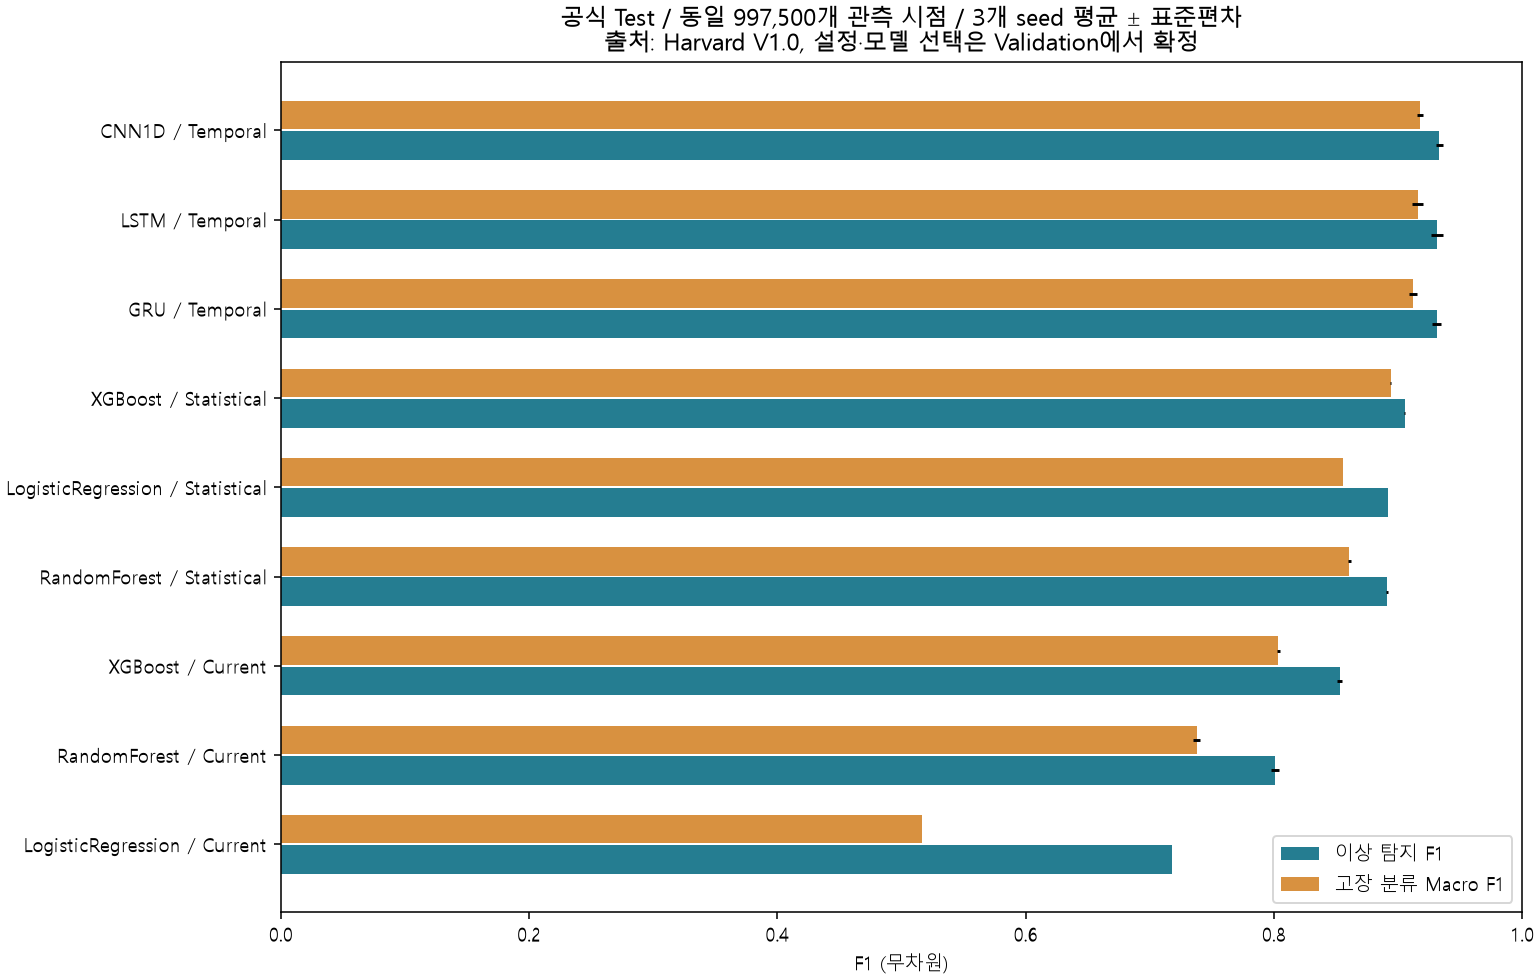

In [2]:
display(Image(filename=str(ROOT/'reports/figures/phase2/model_comparison.png')))
